# E2 – Regresión: Modelado Predictivo del MRR del próximo trimestre (SaaSFlow)

**Objetivo:** estimar `mrr_proximo_trimestre` (USD) de cada cliente B2B mediante un modelo de **Regresión Lineal**, para anticipar fugas de ingresos y priorizar los recursos de Customer Success.

**Estructura del notebook**
1. Fase 1 – Diagnóstico y calidad de datos (EDA)
2. Fase 2 – Limpieza, ingeniería de características, codificación y escalado (sin *data leakage*)
3. Fase 3 – División train/test y entrenamiento
4. Fase 4 – Evaluación (R², MAE) e interpretación financiera
5. Insumos para la presentación ejecutiva

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_validate, KFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler, RobustScaler
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 160)
pd.set_option('display.float_format', '{:,.2f}'.format)
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

## Fase 1 – Diagnóstico y Calidad de Datos (EDA)
### 1.1 Carga del dataset

In [2]:
df_raw = pd.read_csv('clientes_mrr_dataset.csv')
print(f'Dimensiones: {df_raw.shape[0]:,} filas x {df_raw.shape[1]} columnas')
df_raw.head()

Dimensiones: 30,000 filas x 11 columnas


,id_cliente,fecha_registro,sector_empresa,tamano_empresa,tickets_soporte,promedio_sesiones_mes,satisfaccion_nps,duracion_contrato,gasto_mkt_asociado,pago_puntual,mrr_proximo_trimestre
0,CLI-0001,2025-09-14 00:24:49.009633632,Finanzas,Mediana,3.00,34.35,7.00,Mensual,"3,932.34",Si,706.16
1,CLI-0002,2024-02-12 19:17:24.874829152,Tecnologia,Mediana,NaN,28.69,8.00,Mensual,"2,547.83",No,555.95
2,CLI-0003,2021-02-03 13:56:48.713623787,Tecnologia,Pequeña,5.00,50.03,7.00,2 Años,"3,203.23",Si,755.53
3,CLI-0004,2021-08-19 03:21:50.803693456,Educacion,Pequeña,0.00,NaN,9.00,Anual,603.21,No,364.94
4,CLI-0005,2021-09-26 05:21:16.482549416,Educacion,Grande,3.00,NaN,8.00,Anual,864.79,Si,"1,611.93"


In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   id_cliente             30000 non-null  str    
 1   fecha_registro         30000 non-null  str    
 2   sector_empresa         30000 non-null  str    
 3   tamano_empresa         30000 non-null  str    
 4   tickets_soporte        27536 non-null  float64
 5   promedio_sesiones_mes  28455 non-null  float64
 6   satisfaccion_nps       26403 non-null  float64
 7   duracion_contrato      30000 non-null  str    
 8   gasto_mkt_asociado     30000 non-null  float64
 9   pago_puntual           30000 non-null  str    
 10  mrr_proximo_trimestre  30000 non-null  float64
dtypes: float64(5), str(6)
memory usage: 2.5 MB


### 1.2 Porcentaje de valores nulos por variable

,n_nulos,pct_nulos
satisfaccion_nps,3597,11.99
tickets_soporte,2464,8.21
promedio_sesiones_mes,1545,5.15
sector_empresa,0,0.00
fecha_registro,0,0.00
id_cliente,0,0.00
tamano_empresa,0,0.00
duracion_contrato,0,0.00
gasto_mkt_asociado,0,0.00
pago_puntual,0,0.00


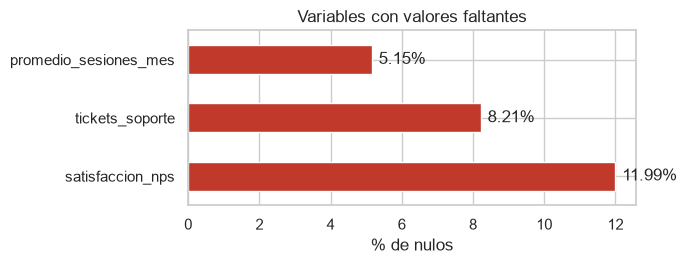

In [4]:
nulos = pd.DataFrame({
    'n_nulos': df_raw.isna().sum(),
    'pct_nulos': (df_raw.isna().mean() * 100).round(2)
}).sort_values('pct_nulos', ascending=False)
display(nulos)

ax = nulos.query('pct_nulos > 0')['pct_nulos'].plot(kind='barh', color='#C0392B', figsize=(7, 2.8))
ax.set_xlabel('% de nulos'); ax.set_title('Variables con valores faltantes')
for i, v in enumerate(nulos.query('pct_nulos > 0')['pct_nulos']):
    ax.text(v + 0.2, i, f'{v:.2f}%', va='center')
plt.tight_layout(); plt.show()

**Hallazgo:** solo 3 variables tienen nulos: `satisfaccion_nps` (~12%), `tickets_soporte` (~8,2%) y `promedio_sesiones_mes` (~5,2%). La variable objetivo y el resto de predictoras están completas, por lo que **no es necesario eliminar filas**: se imputará.

### 1.3 Tipos de datos inconsistentes y duplicados

In [5]:
print('Duplicados de filas completas:', df_raw.duplicated().sum())
print('IDs duplicados:', df_raw['id_cliente'].duplicated().sum())

# Fecha almacenada como texto
print('\nTipo de fecha_registro:', df_raw['fecha_registro'].dtype)
print('Ejemplos:', df_raw['fecha_registro'].head(3).tolist())
fechas = pd.to_datetime(df_raw['fecha_registro'], errors='coerce')
print(f'Fechas no convertibles: {fechas.isna().sum()} | Rango: {fechas.min().date()} a {fechas.max().date()}')

# Variables enteras guardadas como float (por presencia de NaN)
for c in ['tickets_soporte', 'satisfaccion_nps']:
    no_enteros = (df_raw[c].dropna() % 1 != 0).sum()
    print(f'{c}: dtype={df_raw[c].dtype}, valores no enteros={no_enteros}, rango=[{df_raw[c].min()}, {df_raw[c].max()}]')

# Categóricas como texto (no codificadas)
categoricas = ['sector_empresa', 'tamano_empresa', 'duracion_contrato', 'pago_puntual']
for c in categoricas:
    print(f'\n{c} ({df_raw[c].dtype}):', df_raw[c].value_counts().to_dict())

Duplicados de filas completas: 0
IDs duplicados: 0

Tipo de fecha_registro: str
Ejemplos: ['2025-09-14 00:24:49.009633632', '2024-02-12 19:17:24.874829152', '2021-02-03 13:56:48.713623787']
Fechas no convertibles: 0 | Rango: 2021-01-01 a 2025-12-31
tickets_soporte: dtype=float64, valores no enteros=0, rango=[0.0, 12.0]
satisfaccion_nps: dtype=float64, valores no enteros=0, rango=[1.0, 10.0]

sector_empresa (str): {'Tecnologia': 8913, 'Finanzas': 7530, 'Salud': 6018, 'Retail': 4535, 'Educacion': 3004}

tamano_empresa (str): {'Pequeña': 14884, 'Mediana': 10479, 'Grande': 4637}

duracion_contrato (str): {'Mensual': 18087, 'Anual': 8895, '2 Años': 3018}

pago_puntual (str): {'Si': 24088, 'No': 5912}


**Inconsistencias detectadas**

| Variable | Problema | Acción en Fase 2 |
|---|---|---|
| `fecha_registro` | Fecha guardada como **texto** (con nanosegundos) | Convertir a `datetime` y derivar `antiguedad_dias` |
| `tickets_soporte`, `satisfaccion_nps` | Son **enteros** pero vienen como `float64` por los NaN | Imputar con la moda (conserva valores enteros válidos) |
| `sector_empresa` | Categórica **nominal** sin codificar | One-Hot Encoding |
| `tamano_empresa` | Categórica **ordinal** sin codificar | Ordinal Encoding (Pequeña < Mediana < Grande) |
| `duracion_contrato` | Categórica con orden natural (Mensual < Anual < 2 Años) | Mapeo numérico 0/1/2 |
| `pago_puntual` | Texto Si/No | Mapeo binario 1/0 |
| `id_cliente` | Identificador sin poder predictivo | Se excluye del modelo |

No hay duplicados ni fechas inválidas.

### 1.4 Estadísticos, sesgo (asimetría) y outliers en variables numéricas

In [6]:
num_cols = ['tickets_soporte', 'promedio_sesiones_mes', 'satisfaccion_nps', 'gasto_mkt_asociado', 'mrr_proximo_trimestre']

def resumen_outliers(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    li, ls = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return pd.Series({'media': s.mean(), 'mediana': s.median(), 'desv_std': s.std(),
                      'CV_%': s.std() / s.mean() * 100, 'asimetria': s.skew(),
                      'lim_inf_IQR': li, 'lim_sup_IQR': ls,
                      'pct_outliers': ((s < li) | (s > ls)).mean() * 100, 'max': s.max()})

tabla_disp = df_raw[num_cols].apply(lambda s: resumen_outliers(s.dropna())).T
display(tabla_disp)

,media,mediana,desv_std,CV_%,asimetria,lim_inf_IQR,lim_sup_IQR,pct_outliers,max
tickets_soporte,3.01,3.00,1.73,57.71,0.57,-1.00,7.00,1.19,12.00
promedio_sesiones_mes,50.13,36.23,45.06,89.88,1.97,-55.96,141.50,4.80,430.70
satisfaccion_nps,5.91,6.00,2.31,39.10,-0.42,-2.00,14.00,0.00,10.00
gasto_mkt_asociado,"2,551.09","2,541.07","1,416.11",55.51,0.00,"-2,352.19","7,468.38",0.00,"4,999.95"
mrr_proximo_trimestre,710.93,642.60,337.69,47.50,1.05,-197.60,"1,553.29",2.02,"3,200.04"


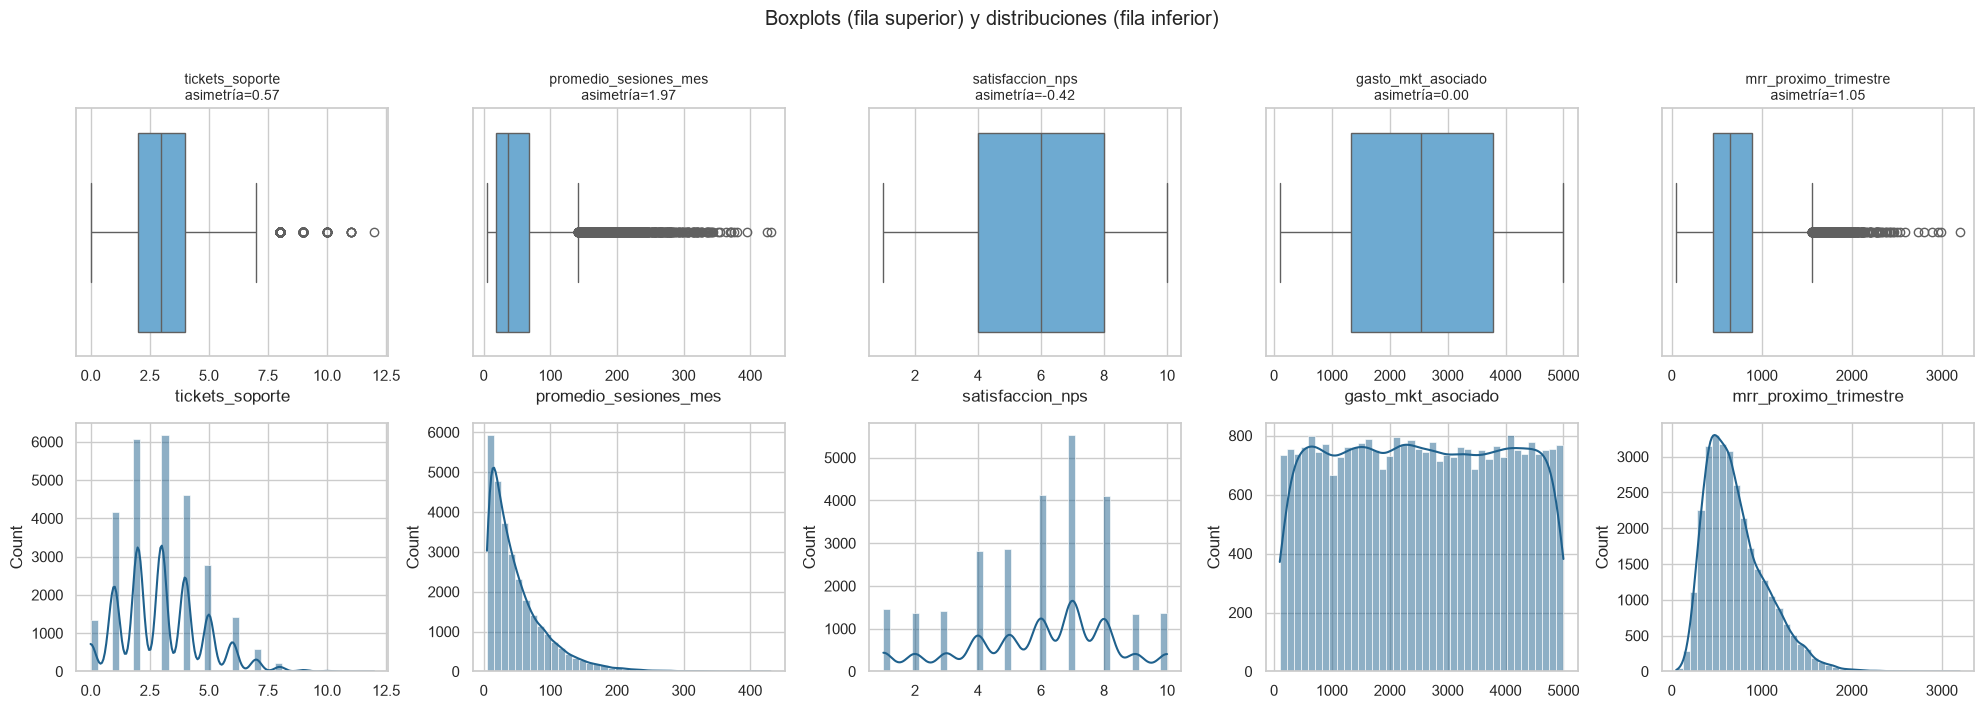

In [7]:
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for i, c in enumerate(num_cols):
    sns.boxplot(x=df_raw[c], ax=axes[0, i], color='#5DADE2')
    axes[0, i].set_title(f'{c}\nasimetría={df_raw[c].skew():.2f}', fontsize=10)
    sns.histplot(df_raw[c], ax=axes[1, i], kde=True, color='#1F618D', bins=40)
    axes[1, i].set_xlabel('')
plt.suptitle('Boxplots (fila superior) y distribuciones (fila inferior)', y=1.01)
plt.tight_layout(); plt.show()

**Interpretación**
- `promedio_sesiones_mes` es la variable más **sesgada a la derecha** (asimetría ≈ 2) y con más outliers por IQR (~4,8% de los valores registrados; máximo ≈ 430 sesiones vs. mediana ≈ 36). Son clientes de uso intensivo plausibles, no errores, por lo que **no se eliminan**: se usará **RobustScaler** (mediana/IQR), que no se distorsiona por esos extremos, y la **mediana** para imputar.
- `mrr_proximo_trimestre` (objetivo) también tiene sesgo positivo (≈ 1,05) y ~2% de outliers: son clientes grandes de alto valor, información de negocio legítima que se mantiene.
- `tickets_soporte` presenta asimetría leve (≈ 0,57); `satisfaccion_nps` es levemente asimétrica a la izquierda (concentrada en 6–8); `gasto_mkt_asociado` es prácticamente uniforme (sin outliers).

### 1.5 Relación de las variables con el MRR futuro

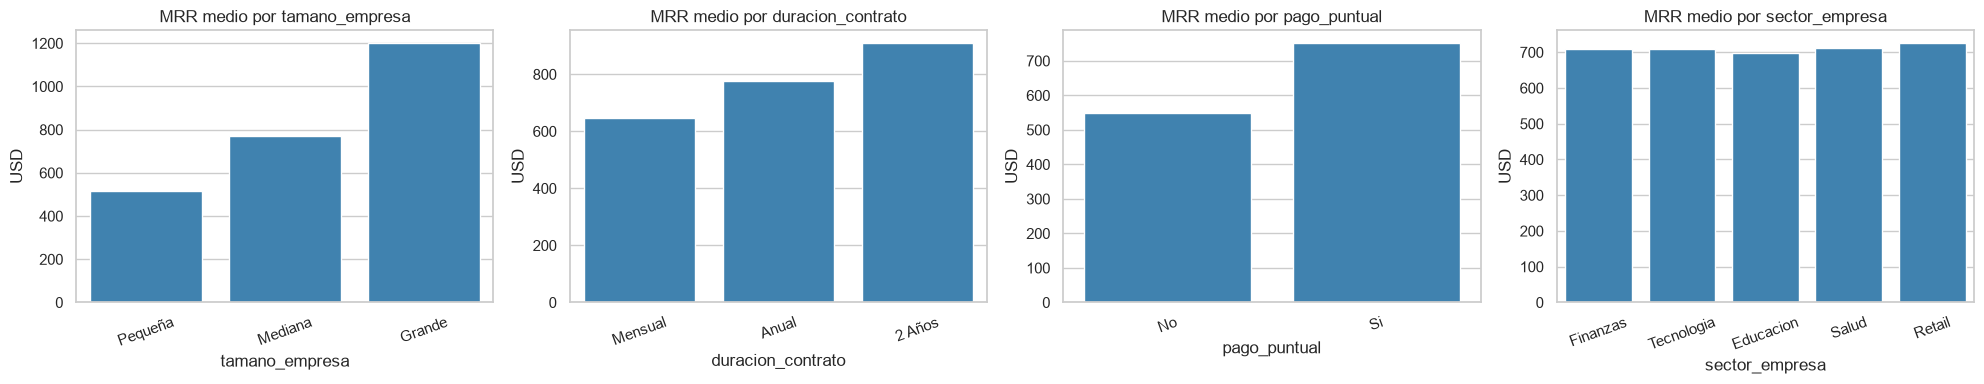

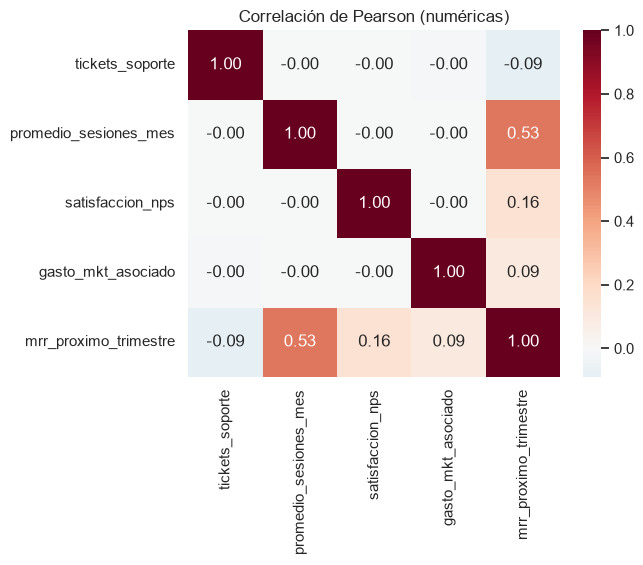

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
orden = {'tamano_empresa': ['Pequeña', 'Mediana', 'Grande'],
         'duracion_contrato': ['Mensual', 'Anual', '2 Años'],
         'pago_puntual': ['No', 'Si'],
         'sector_empresa': None}
for ax, (c, o) in zip(axes, orden.items()):
    sns.barplot(data=df_raw, x=c, y='mrr_proximo_trimestre', order=o, ax=ax, color='#2E86C1', errorbar=None)
    ax.set_title(f'MRR medio por {c}'); ax.set_ylabel('USD'); ax.tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()

corr = df_raw[num_cols].corr()
plt.figure(figsize=(6, 4.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0)
plt.title('Correlación de Pearson (numéricas)'); plt.show()

El tamaño de empresa, la duración del contrato, el pago puntual y las sesiones de uso muestran una relación clara con el MRR; el sector prácticamente no discrimina (medias muy similares).

## Fase 2 – Limpieza y Tratamiento de Datos

**Estrategia anti-*data leakage*:**
1. Las transformaciones **determinísticas fila a fila** (convertir fecha → antigüedad con una fecha de referencia fija, mapear Si/No, mapear tipo de contrato) no aprenden nada de los datos, por lo que pueden hacerse antes de dividir.
2. Todo lo que **aprende parámetros** de los datos (medianas/modas de imputación, medias/desviaciones del escalado, categorías del One-Hot) se encapsula en un `Pipeline` + `ColumnTransformer` que se ajusta **solo con el conjunto de entrenamiento** y luego se aplica al de prueba.

### 2.1 Ingeniería de características y mapeos determinísticos

In [9]:
df = df_raw.copy()

# Fecha texto -> datetime -> antigüedad en días
df['fecha_registro'] = pd.to_datetime(df['fecha_registro'])
FECHA_REFERENCIA = pd.Timestamp('2026-01-01')   # cierre del periodo observado (último registro: 2025-12-31)
df['antiguedad_dias'] = (FECHA_REFERENCIA - df['fecha_registro']).dt.days

# Mapeos a formato numérico/binario
df['duracion_contrato_num'] = df['duracion_contrato'].map({'Mensual': 0, 'Anual': 1, '2 Años': 2})
df['pago_puntual_bin'] = df['pago_puntual'].map({'No': 0, 'Si': 1})

assert df[['duracion_contrato_num', 'pago_puntual_bin']].isna().sum().sum() == 0
df[['fecha_registro', 'antiguedad_dias', 'duracion_contrato', 'duracion_contrato_num', 'pago_puntual', 'pago_puntual_bin']].head()

,fecha_registro,antiguedad_dias,duracion_contrato,duracion_contrato_num,pago_puntual,pago_puntual_bin
0,2025-09-14 00:24:49.009633632,108,Mensual,0,Si,1
1,2024-02-12 19:17:24.874829152,688,Mensual,0,No,0
2,2021-02-03 13:56:48.713623787,1792,2 Años,2,Si,1
3,2021-08-19 03:21:50.803693456,1595,Anual,1,No,0
4,2021-09-26 05:21:16.482549416,1557,Anual,1,Si,1


In [10]:
df['antiguedad_dias'].describe()

count   30,000.00
mean       913.00
std        526.86
min          1.00
25%        457.00
50%        913.00
75%      1,369.00
max      1,826.00
Name: antiguedad_dias, dtype: float64

## Fase 3 – Construcción del Modelo
### 3.1 División entrenamiento / prueba (80% / 20%)
Se divide **antes** de imputar, codificar con parámetros aprendidos o escalar.

In [11]:
TARGET = 'mrr_proximo_trimestre'
features = ['tickets_soporte', 'promedio_sesiones_mes', 'satisfaccion_nps', 'gasto_mkt_asociado',
            'antiguedad_dias', 'tamano_empresa', 'sector_empresa', 'duracion_contrato_num', 'pago_puntual_bin']

X = df[features]
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE)
print(f'Train: {X_train.shape} | Test: {X_test.shape}')
print(f'MRR medio train: {y_train.mean():,.2f} | MRR medio test: {y_test.mean():,.2f}')

Train: (24000, 9) | Test: (6000, 9)
MRR medio train: 711.58 | MRR medio test: 708.31


### 3.2 Preprocesamiento (ajustado solo en train) – justificación

| Grupo | Variables | Imputación | Codificación / Escalado | Justificación |
|---|---|---|---|---|
| Continua sesgada | `promedio_sesiones_mes` | **Mediana** | **RobustScaler** | Asimetría ≈ 2 y outliers: la mediana y el IQR no se distorsionan con los extremos |
| Discretas (conteo / escala) | `tickets_soporte`, `satisfaccion_nps` | **Moda** (valor más frecuente) | StandardScaler | Son enteros acotados; la moda conserva un valor real y válido de la escala |
| Continuas sin nulos | `gasto_mkt_asociado`, `antiguedad_dias` | – | StandardScaler | Distribuciones sin outliers; igualar magnitudes (miles de USD vs. días) |
| Ordinal | `tamano_empresa` | – | **OrdinalEncoder** (Pequeña=0, Mediana=1, Grande=2) + StandardScaler | Existe jerarquía natural |
| Nominal | `sector_empresa` | – | **OneHotEncoder** (`drop='first'`) | Sin orden; se elimina una categoría para evitar multicolinealidad perfecta (trampa de la dummy) |
| Mapeadas | `duracion_contrato_num`, `pago_puntual_bin` | – | Se dejan en 0/1/2 y 0/1 | Escala pequeña e interpretable: el coeficiente se lee directamente en USD |

In [12]:
preprocesador = ColumnTransformer(transformers=[
    ('sesiones', Pipeline([('imputar', SimpleImputer(strategy='median')),
                           ('escalar', RobustScaler())]), ['promedio_sesiones_mes']),
    ('discretas', Pipeline([('imputar', SimpleImputer(strategy='most_frequent')),
                            ('escalar', StandardScaler())]), ['tickets_soporte', 'satisfaccion_nps']),
    ('continuas', StandardScaler(), ['gasto_mkt_asociado', 'antiguedad_dias']),
    ('ordinal', Pipeline([('codificar', OrdinalEncoder(categories=[['Pequeña', 'Mediana', 'Grande']])),
                          ('escalar', StandardScaler())]), ['tamano_empresa']),
    ('nominal', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), ['sector_empresa']),
    ('mapeadas', 'passthrough', ['duracion_contrato_num', 'pago_puntual_bin']),
])

modelo = Pipeline([('preprocesamiento', preprocesador),
                   ('regresion', LinearRegression())])
modelo

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocesamiento', ...), ('regresion', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('sesiones', ...), ('discretas', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: 

### 3.3 Entrenamiento de la Regresión Lineal

In [13]:
modelo.fit(X_train, y_train)

# Verificación: valores aprendidos SOLO con train
pre = modelo.named_steps['preprocesamiento']
print('Mediana de sesiones aprendida (train):', pre.named_transformers_['sesiones']['imputar'].statistics_)
print('Modas tickets / NPS aprendidas (train):', pre.named_transformers_['discretas']['imputar'].statistics_)

X_train_transf = pd.DataFrame(pre.transform(X_train), columns=pre.get_feature_names_out(), index=X_train.index)
print('\nNulos tras preprocesar:', X_train_transf.isna().sum().sum())
X_train_transf.head()

Mediana de sesiones aprendida (train): [36.55652531]
Modas tickets / NPS aprendidas (train): [3. 7.]

Nulos tras preprocesar: 0


,sesiones__promedio_sesiones_mes,discretas__tickets_soporte,discretas__satisfaccion_nps,continuas__gasto_mkt_asociado,continuas__antiguedad_dias,ordinal__tamano_empresa,nominal__sector_empresa_Finanzas,nominal__sector_empresa_Retail,nominal__sector_empresa_Salud,nominal__sector_empresa_Tecnologia,mapeadas__duracion_contrato_num,mapeadas__pago_puntual_bin
21753,1.09,-1.20,0.44,-0.83,1.51,0.47,0.00,0.00,0.00,1.00,1.00,1.00
251,1.01,-1.80,-0.02,1.54,0.98,0.47,0.00,0.00,0.00,1.00,0.00,0.00
22941,-0.57,-1.20,0.89,-1.47,-1.74,-0.90,0.00,0.00,0.00,0.00,0.00,0.00
618,-0.12,-0.60,-0.02,-0.14,-0.54,1.84,0.00,1.00,0.00,0.00,0.00,0.00
17090,-0.53,-1.20,-0.48,-1.34,0.92,-0.90,0.00,1.00,0.00,0.00,1.00,1.00


In [14]:
# Validación cruzada (5 folds) SOLO sobre train: estabilidad del modelo
cv = cross_validate(modelo, X_train, y_train, cv=KFold(5, shuffle=True, random_state=RANDOM_STATE),
                    scoring={'r2': 'r2', 'mae': 'neg_mean_absolute_error'})
print(f"CV R²  : {cv['test_r2'].mean():.4f} ± {cv['test_r2'].std():.4f}")
print(f"CV MAE : {-cv['test_mae'].mean():,.2f} ± {cv['test_mae'].std():.2f} USD")

CV R²  : 0.9187 ± 0.0024
CV MAE : 69.60 ± 1.34 USD


## Fase 4 – Evaluación e Interpretación de Métricas (conjunto de prueba)

In [15]:
y_pred = modelo.predict(X_test)

r2   = r2_score(y_test, y_pred)
mae  = mean_absolute_error(y_test, y_pred)
rmse = root_mean_squared_error(y_test, y_pred)
mae_pct = mae / y_test.mean() * 100

# Línea base ingenua: predecir siempre el MRR promedio de train
base = DummyRegressor(strategy='mean').fit(X_train, y_train)
mae_base = mean_absolute_error(y_test, base.predict(X_test))

# Error a nivel de cartera (suma de MRR)
total_real, total_pred = y_test.sum(), y_pred.sum()

metricas = pd.DataFrame({
    'Métrica': ['R² (test)', 'MAE (test, USD)', 'RMSE (test, USD)', 'MAE como % del MRR medio',
                'MAE línea base (predecir promedio)', 'Reducción de error vs línea base',
                'MRR total real (test)', 'MRR total predicho (test)', 'Desvío agregado de cartera'],
    'Valor': [f'{r2:.4f}', f'{mae:,.2f}', f'{rmse:,.2f}', f'{mae_pct:.1f}%',
              f'{mae_base:,.2f}', f'{(1 - mae / mae_base) * 100:.1f}%',
              f'{total_real:,.0f}', f'{total_pred:,.0f}', f'{(total_pred / total_real - 1) * 100:+.2f}%']
})
display(metricas)

,Métrica,Valor
0,R² (test),0.9240
1,"MAE (test, USD)",68.32
2,"RMSE (test, USD)",93.90
3,MAE como % del MRR medio,9.6%
4,MAE línea base (predecir promedio),266.61
5,Reducción de error vs línea base,74.4%
6,MRR total real (test),"4,249,878"
7,MRR total predicho (test),"4,246,835"
8,Desvío agregado de cartera,-0.07%


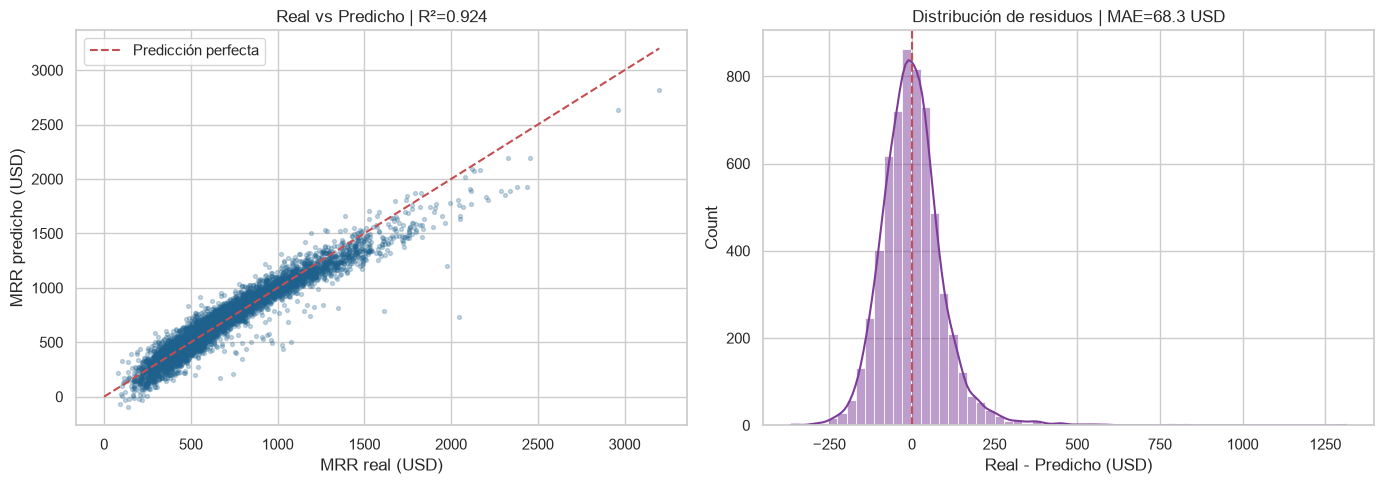

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(y_test, y_pred, alpha=0.25, s=8, color='#1F618D')
lim = [0, max(y_test.max(), y_pred.max())]
axes[0].plot(lim, lim, 'r--', label='Predicción perfecta')
axes[0].set_xlabel('MRR real (USD)'); axes[0].set_ylabel('MRR predicho (USD)')
axes[0].set_title(f'Real vs Predicho | R²={r2:.3f}'); axes[0].legend()

residuos = y_test - y_pred
sns.histplot(residuos, bins=60, kde=True, ax=axes[1], color='#7D3C98')
axes[1].axvline(0, color='r', ls='--')
axes[1].set_title(f'Distribución de residuos | MAE={mae:,.1f} USD'); axes[1].set_xlabel('Real - Predicho (USD)')
plt.tight_layout(); plt.show()

In [17]:
# Error por segmento: ¿dónde se equivoca más el modelo?
eval_df = X_test.copy()
eval_df['real'] = y_test; eval_df['pred'] = y_pred; eval_df['abs_err'] = (y_test - y_pred).abs()
seg = (eval_df.groupby('tamano_empresa')
       .agg(clientes=('real', 'size'), mrr_real_medio=('real', 'mean'), MAE=('abs_err', 'mean'))
       .reindex(['Pequeña', 'Mediana', 'Grande']))
seg['MAE_%'] = seg['MAE'] / seg['mrr_real_medio'] * 100
seg

,clientes,mrr_real_medio,MAE,MAE_%
tamano_empresa,,,,
Pequeña,2969,512.17,60.46,11.80
Mediana,2097,766.18,69.23,9.04
Grande,934,"1,201.89",91.24,7.59


### 4.1 Interpretación en el contexto financiero de SaaSFlow
*(los valores exactos se imprimen en las celdas anteriores; con `random_state=42`: R² ≈ 0,92 y MAE ≈ 68 USD)*

- **R² ≈ 0,92:** las 9 variables del cliente (uso, tamaño, contrato, pago, satisfacción, soporte, etc.) explican cerca del **92% de la variabilidad del MRR del próximo trimestre** entre clientes. Solo ~8% depende de factores no capturados (negociaciones, eventos puntuales, ruido). Para planificación comercial es un poder explicativo alto. La validación cruzada en train entrega un valor casi idéntico, por lo que **no hay sobreajuste**.
- **MAE ≈ 68 USD:** en promedio, **el modelo se equivoca en aproximadamente 68 USD por cliente** al proyectar su MRR mensual, lo que equivale a ~10% del MRR medio (~708 USD). Comparado con "predecir el promedio para todos" (MAE ≈ 267 USD), el error se reduce en ~75%.
- **A nivel de cartera** los errores positivos y negativos se compensan: el MRR total proyectado del conjunto de prueba se desvía apenas ~0,1% del real, lo que hace al modelo útil para el **forecast de ingresos agregado**.
- **Precaución:** el error relativo es mayor en clientes pequeños (MRR bajo) y el RMSE (> MAE) indica algunos errores grandes en clientes de alto valor; para decisiones individuales de cuentas grandes conviene complementar con el criterio del Account Manager.

### 4.2 Importancia de variables (coeficientes)

Intercepto: 431.03 USD


,coef_modelo,efecto_por_unidad_original_USD,unidad
ordinal__tamano_empresa,236.22,323.36,1 nivel de tamaño
mapeadas__pago_puntual_bin,204.34,204.34,paga puntual vs no
sesiones__promedio_sesiones_mes,184.39,3.99,1 sesión/mes
mapeadas__duracion_contrato_num,128.44,128.44,1 nivel de contrato
discretas__satisfaccion_nps,47.94,21.83,1 punto NPS
continuas__gasto_mkt_asociado,32.97,0.02,1 USD de marketing
discretas__tickets_soporte,-29.43,-17.65,1 ticket
nominal__sector_empresa_Retail,2.46,2.46,vs Educación
nominal__sector_empresa_Finanzas,0.67,0.67,vs Educación
continuas__antiguedad_dias,-0.28,-0.00,1 día de antigüedad


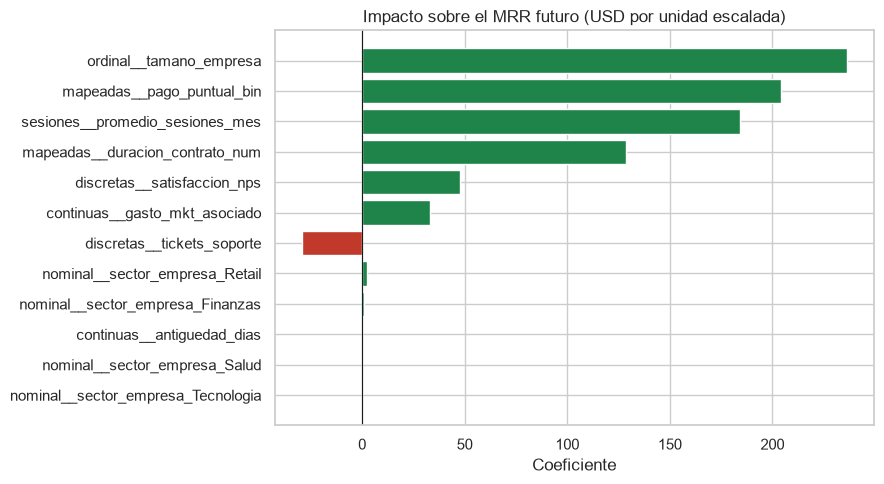

In [18]:
nombres = pre.get_feature_names_out()
coef = pd.Series(modelo.named_steps['regresion'].coef_, index=nombres)

# Traducción a efecto por unidad original (USD de MRR por unidad de la variable)
esc = {
    'sesiones__promedio_sesiones_mes': pre.named_transformers_['sesiones']['escalar'].scale_[0],
    'discretas__tickets_soporte': pre.named_transformers_['discretas']['escalar'].scale_[0],
    'discretas__satisfaccion_nps': pre.named_transformers_['discretas']['escalar'].scale_[1],
    'continuas__gasto_mkt_asociado': pre.named_transformers_['continuas'].scale_[0],
    'continuas__antiguedad_dias': pre.named_transformers_['continuas'].scale_[1],
    'ordinal__tamano_empresa': pre.named_transformers_['ordinal']['escalar'].scale_[0],
}
tabla_coef = pd.DataFrame({'coef_modelo': coef})
tabla_coef['efecto_por_unidad_original_USD'] = [coef[n] / esc.get(n, 1) for n in nombres]
tabla_coef['unidad'] = ['1 sesión/mes', '1 ticket', '1 punto NPS', '1 USD de marketing', '1 día de antigüedad',
                        '1 nivel de tamaño'] + ['vs Educación'] * 4 + ['1 nivel de contrato', 'paga puntual vs no']
tabla_coef = tabla_coef.reindex(tabla_coef['coef_modelo'].abs().sort_values(ascending=False).index)
print(f"Intercepto: {modelo.named_steps['regresion'].intercept_:,.2f} USD")
display(tabla_coef)

plt.figure(figsize=(9, 5))
colores = ['#1E8449' if v > 0 else '#C0392B' for v in tabla_coef['coef_modelo']]
plt.barh(tabla_coef.index[::-1], tabla_coef['coef_modelo'][::-1], color=colores[::-1])
plt.axvline(0, color='k', lw=0.8)
plt.title('Impacto sobre el MRR futuro (USD por unidad escalada)'); plt.xlabel('Coeficiente')
plt.tight_layout(); plt.show()

**Lectura de negocio de los coeficientes**
- **Tamaño de empresa** y **pago puntual** son los motores más fuertes: un cliente que paga a tiempo proyecta ~200 USD/mes más que uno que no, *ceteris paribus*.
- **Uso de la plataforma (sesiones)**: cada sesión mensual adicional se asocia a ~+4 USD de MRR; es la palanca más accionable para Customer Success.
- **Duración del contrato**: cada escalón (Mensual → Anual → 2 Años) suma ~128 USD/mes.
- **Satisfacción (NPS)**: ~+22 USD por punto; **tickets de soporte**: ~−18 USD por ticket (fricción = menor ingreso).
- **Sector** y **antigüedad** tienen efecto prácticamente nulo; el gasto de marketing tiene un efecto positivo pero pequeño (~+2 USD de MRR por cada 100 USD invertidos), lo que sugiere revisar su eficiencia.

## 5. Insumos para Customer Success: priorización de cartera

In [19]:
# Aplicamos el modelo a toda la cartera para segmentar riesgo (uso operativo, no evaluación)
cartera = df[['id_cliente'] + features].copy()
cartera['mrr_predicho'] = modelo.predict(df[features])

# Para segmentar usamos las MISMAS modas aprendidas en train (los NaN no deben quedar fuera del análisis de riesgo)
moda_tickets, moda_nps = pre.named_transformers_['discretas']['imputar'].statistics_
cartera['tickets_soporte'] = cartera['tickets_soporte'].fillna(moda_tickets)
cartera['satisfaccion_nps'] = cartera['satisfaccion_nps'].fillna(moda_nps)

def segmento(r):
    riesgo = (r['pago_puntual_bin'] == 0) or (r['satisfaccion_nps'] <= 4) or (r['tickets_soporte'] >= 6)
    alto_valor = r['mrr_predicho'] >= cartera['mrr_predicho'].quantile(0.75)
    if riesgo and alto_valor: return '1. Alto valor en riesgo'
    if riesgo: return '2. Valor medio/bajo en riesgo'
    if r['duracion_contrato_num'] == 0 and alto_valor: return '3. Alto valor mensual (upsell a anual)'
    return '4. Estable'

cartera['segmento_cs'] = cartera.apply(segmento, axis=1)
resumen_cs = (cartera.groupby('segmento_cs')
              .agg(clientes=('id_cliente', 'size'), mrr_predicho_total=('mrr_predicho', 'sum'),
                   mrr_predicho_medio=('mrr_predicho', 'mean')))
resumen_cs['pct_mrr'] = resumen_cs['mrr_predicho_total'] / resumen_cs['mrr_predicho_total'].sum() * 100
resumen_cs

,clientes,mrr_predicho_total,mrr_predicho_medio,pct_mrr
segmento_cs,,,,
1. Alto valor en riesgo,2342,"2,643,402.05","1,128.69",12.40
2. Valor medio/bajo en riesgo,10641,"5,462,790.85",513.37,25.62
3. Alto valor mensual (upsell a anual),2523,"2,847,501.51","1,128.62",13.35
4. Estable,14494,"10,371,051.73",715.54,48.63


In [20]:
# Escenario simple de ROI: cuánto MRR se gana si CS logra subir el uso o la puntualidad de pago
efecto_sesion = tabla_coef.loc['sesiones__promedio_sesiones_mes', 'efecto_por_unidad_original_USD']
efecto_pago   = tabla_coef.loc['mapeadas__pago_puntual_bin', 'efecto_por_unidad_original_USD']
en_riesgo = cartera[cartera['segmento_cs'].str.startswith('1')]
no_puntuales = en_riesgo['pago_puntual_bin'].eq(0).sum()
print(f'Clientes alto valor en riesgo: {len(en_riesgo):,} | MRR proyectado: {en_riesgo.mrr_predicho.sum():,.0f} USD/mes')
print(f'+10 sesiones/mes en ese grupo  => +{efecto_sesion * 10 * len(en_riesgo):,.0f} USD de MRR mensual estimado')
print(f'Convertir a pago puntual al 30% de sus {no_puntuales:,} morosos => +{efecto_pago * 0.3 * no_puntuales:,.0f} USD de MRR mensual estimado')

Clientes alto valor en riesgo: 2,342 | MRR proyectado: 2,643,402 USD/mes
+10 sesiones/mes en ese grupo  => +93,457 USD de MRR mensual estimado
Convertir a pago puntual al 30% de sus 750 morosos => +45,976 USD de MRR mensual estimado


## Conclusiones
1. **Calidad de datos:** nulos moderados (5–12%) en 3 variables, imputados con mediana/moda aprendidas solo en train; fecha en texto transformada a antigüedad; categóricas codificadas según su naturaleza; escalado robusto para la variable sesgada. Sin *data leakage* gracias al `Pipeline`.
2. **Modelo:** la Regresión Lineal explica ~92% de la variación del MRR futuro con un error medio de ~68 USD por cliente (~10%), y un desvío agregado de cartera de ~0,1%.
3. **Palancas de negocio:** tamaño de cuenta, pago puntual, uso de la plataforma, duración de contrato y satisfacción. Las tres últimas son **accionables** por Customer Success.